# Экзаменационная задача №2. Расчет критической массы и ценности социальной сети

**Курс:** Экономика информатизации (лекция №3 «Сетевые эффекты и критическая масса»)
**Студент:** Солдатов Сергей Юрьевич
**Группа:** ПИ4-1
**Дата:** 2026-11-17

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №02: РАСЧЕТ КРИТИЧЕСКОЙ МАССЫ И ЦЕННОСТИ
#                             СОЦИАЛЬНОЙ СЕТИ
# ======================================================================
# Дата: 2026-11-17
# Студент: Солдатов Сергей Юрьевич
# Группа: ПИ4-1
# ======================================================================

# Подключаем библиотеки: numpy/pandas — расчеты и таблицы, matplotlib — графики
import json
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Единый стиль графиков: светлый фон, тонкая сетка, без лишних рамок
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

# Цвета рядов (фиксированный порядок)
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

# Папка для сохранения графиков и итоговых показателей
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

MLN = 1_000_000  # для перевода рублей в миллионы

pd.options.display.float_format = "{:,.2f}".format

## 0. Экономическая постановка задачи

**Проблема.** Компания «ГородСоцСеть» запускает социальную сеть для города с населением 1 млн человек. Социальная сеть —
продукт с прямым сетевым эффектом: ее ценность для каждого пользователя зависит от того, сколько людей в ней уже есть.
Пока пользователей мало, сеть малополезна и убыточна; после достижения **критической массы** она начинает расти сама.

**Актуальность.** Для платформенного бизнеса главный вопрос — не «сколько стоит разработка», а «хватит ли денег дожить
до критической массы». От ответа зависит объем инвестиций и стратегия запуска.

**Цель.** Оценить экономическую ценность сети, определить момент достижения критической массы и эффективность проекта
на горизонте 36 месяцев.

**Задачи:**
1. найти критическую массу и срок ее достижения;
2. рассчитать ценность сети по закону Мэткалфа, доход и прибыль по месяцам;
3. рассчитать NPV, его чувствительность к темпам роста и безубыточный ARPU;
4. оценить маркетинговые инвестиции для ускорения и сформулировать стратегию.

## 1. Исходные данные

### 1.1. Параметры проекта (из условия задачи)

In [2]:
# Все исходные данные собраны в одном словаре, чтобы их было легко менять в сценариях
BASE = {
    "market": 1_000_000,       # M — общий потенциал рынка, чел.
    "n0": 5_000,               # N0 — начальное число пользователей, чел.
    "growth_before": 0.03,     # ежемесячный темп прироста до критической массы
    "growth_after": 0.15,      # ежемесячный темп прироста после критической массы
    "k": 0.005,                # коэффициент ценности сети, руб./пользователь²
    "fixed_cost": 2_000_000,   # затраты на поддержание сети, руб./мес.
    "cac": 500,                # стоимость привлечения одного пользователя, руб.
    "arpu": 15,                # средний доход с пользователя, руб./мес.
    "horizon": 36,             # горизонт, мес.
    "rate": 0.01,              # ставка дисконтирования, в месяц (12% годовых)
}

source_table = pd.DataFrame({
    "Параметр": [
        "Потенциал рынка (M), чел.", "Начальное число пользователей (N0), чел.",
        "Темп прироста до критической массы, в мес.", "Темп прироста после критической массы, в мес.",
        "Коэффициент ценности сети (k), руб./польз.²", "Затраты на поддержание, руб./мес.",
        "Стоимость привлечения пользователя (CAC), руб.", "Доход с пользователя (ARPU), руб./мес.",
        "Горизонт, мес.", "Ставка дисконтирования, в мес.",
    ],
    "Значение": ["1 000 000", "5 000", "3%", "15%", "0,005", "2 000 000", "500", "15", "36", "1%"],
})
display(source_table)

,Параметр,Значение
0,"Потенциал рынка (M), чел.",1 000 000
1,"Начальное число пользователей (N0), чел.",5 000
2,"Темп прироста до критической массы, в мес.",3%
3,"Темп прироста после критической массы, в мес.",15%
4,"Коэффициент ценности сети (k), руб./польз.²","0,005"
5,"Затраты на поддержание, руб./мес.",2 000 000
6,"Стоимость привлечения пользователя (CAC), руб.",500
7,"Доход с пользователя (ARPU), руб./мес.",15
8,"Горизонт, мес.",36
9,"Ставка дисконтирования, в мес.",1%


### 1.2. Справочные данные и принятые допущения

| № | Допущение | Обоснование |
|---|---|---|
| Д1 | Критическая масса — число пользователей, при котором текущий доход покрывает затраты на поддержание: $N_{крит} = F / ARPU$ | Затраты на поддержание — постоянные, их нужно покрывать всегда. CAC — разовая инвестиция в рост, а не затраты на поддержание. Почему CAC нельзя просто добавить в формулу — показано в разделе 3.2 |
| Д2 | Рост помесячный: $N_t = \min(M;\ N_{t-1}(1+g))$; темп $g$ = 3%, пока $N_{t-1} < N_{крит}$, далее 15% | Экспоненциальный рост по условию; число пользователей не может превысить население города |
| Д3 | CAC платится за каждого нового пользователя на всем горизонте | Формула прибыли из условия: $П = R - F - CAC \times$ новые пользователи. Вариант с бесплатным (органическим) ростом после критической массы рассмотрен в разделе 3.7 |
| Д4 | Оттока пользователей нет | В условии отток не задан |
| Д5 | Денежные потоки приходят в конце месяца, месяцы 1–36; затраты на первые 5 000 пользователей уже понесены | Стандартное упрощение для NPV |
| Д6 | Ценность по Мэткалфу — оценка полезности сети для пользователей (и потенциальной стоимости компании), а не денежный поток; в NPV она не входит | В NPV входят только реальные доходы и расходы |

## 2. Математическая модель

**Критическая масса.** Условие самоподдержания: доход ≥ затраты на поддержание + расходы на привлечение. При темпе
прироста $g$ новые пользователи за месяц — это $g \cdot N$, поэтому:

$$ARPU \cdot N \ge F + CAC \cdot g \cdot N \quad\Rightarrow\quad N_{крит}(g) = \frac{F}{ARPU - CAC \cdot g}.$$

Если рост не оплачивается из текущего дохода ($g = 0$ в формуле), получаем базовое определение $N_{крит} = F / ARPU$.

**Время достижения** при экспоненциальном росте $N_t = N_0 (1+g)^t$:

$$t_{крит} = \frac{\ln(N_{крит} / N_0)}{\ln(1+g)}.$$

**Ценность сети (закон Мэткалфа):** $V(N) = k \cdot N^2$.

**Доход:** $R_t = ARPU \cdot N_t$. **Прибыль:** $П_t = R_t - F - CAC \cdot (N_t - N_{t-1})$.

**NPV:** $NPV = \sum_{t=1}^{36} \dfrac{П_t}{(1+r)^t}$, где $r$ = 1% в месяц.

**Почему эти методы.** Закон Мэткалфа — базовая модель прямого сетевого эффекта (лекция №3, п. 3). NPV нужен, потому что
платформа сначала несет убытки, а доходы получает позже, и сравнивать их можно только с учетом дисконтирования.

## 3. Расчеты

### 3.1. Модель роста сети

In [3]:
def critical_mass(p, growth=0.0):
    """Критическая масса: число пользователей, при котором доход покрывает затраты.

    growth = 0 — базовое определение (покрываются затраты на поддержание);
    growth > 0 — дополнительно из дохода оплачивается привлечение growth*N новых пользователей.
    Возвращает бесконечность, если доход с пользователя не покрывает расходы на рост.
    """
    margin_per_user = p["arpu"] - p["cac"] * growth
    return p["fixed_cost"] / margin_per_user if margin_per_user > 1e-9 else math.inf


def simulate(p, horizon=None, boost_users=0, organic_after=False):
    """Помесячная модель сети. Возвращает таблицу с пользователями, доходами и прибылью.

    boost_users   — число пользователей, купленных разово в момент 0 (маркетинговый «рывок»);
    organic_after — если True, после критической массы рост органический (CAC не платится).
    """
    horizon = horizon or p["horizon"]
    n_crit = critical_mass(p)
    users = p["n0"] + boost_users
    rows = [{"Месяц": 0, "Пользователи": users, "Новые": boost_users, "Темп": np.nan,
             "Доход": 0.0, "Поддержание": 0.0, "Привлечение": p["cac"] * boost_users}]
    for month in range(1, horizon + 1):
        reached = users >= n_crit                          # достигнута ли критическая масса
        growth = p["growth_after"] if reached else p["growth_before"]
        new_total = min(p["market"], users * (1 + growth))  # ограничение емкостью рынка
        new_users = new_total - users
        paid = 0.0 if (organic_after and reached) else p["cac"] * new_users
        users = new_total
        rows.append({"Месяц": month, "Пользователи": users, "Новые": new_users, "Темп": growth,
                     "Доход": p["arpu"] * users, "Поддержание": p["fixed_cost"], "Привлечение": paid})
    df = pd.DataFrame(rows).set_index("Месяц")
    df["Ценность (Мэткалф)"] = p["k"] * df["Пользователи"] ** 2
    df["Прибыль"] = df["Доход"] - df["Поддержание"] - df["Привлечение"]
    df["Дисконт"] = 1 / (1 + p["rate"]) ** df.index
    df["Дисконтированная прибыль"] = df["Прибыль"] * df["Дисконт"]
    return df


def npv(df):
    """NPV проекта: сумма дисконтированных месячных прибылей."""
    return df["Дисконтированная прибыль"].sum()


def month_reached(df, threshold):
    """Первый месяц, когда число пользователей достигло порога (None — не достигло)."""
    hit = df.index[df["Пользователи"] >= threshold - 1e-6]
    return int(hit[0]) if len(hit) else None

### 3.2. Часть 1. Критическая масса и время ее достижения (задания 1–2)

In [4]:
n_crit = critical_mass(BASE)
print(f"Критическая масса: N_крит = 2 000 000 / 15 = {n_crit:,.1f}, то есть {math.ceil(n_crit):,} пользователей (округление вверх)")
print(f"Это {n_crit / BASE['market']:.1%} населения города и в {n_crit / BASE['n0']:.1f} раза больше стартовой базы")

# Что будет, если расходы на привлечение тоже оплачивать из текущего дохода
print("\nКритическая масса, если рост оплачивается из дохода:")
for g in (0.0, 0.01, 0.02, 0.03, 0.05):
    value = critical_mass(BASE, g)
    text = f"{value:,.0f}" if math.isfinite(value) else "не существует"
    print(f"   темп {g:.0%}: расход на рост {BASE['cac'] * g:4.1f} руб./польз. в мес. -> N_крит = {text}")
print(f"Предельный самофинансируемый темп роста: ARPU / CAC = {BASE['arpu'] / BASE['cac']:.1%} в месяц")

Критическая масса: N_крит = 2 000 000 / 15 = 133,333.3, то есть 133,334 пользователей (округление вверх)
Это 13.3% населения города и в 26.7 раза больше стартовой базы

Критическая масса, если рост оплачивается из дохода:
   темп 0%: расход на рост  0.0 руб./польз. в мес. -> N_крит = 133,333
   темп 1%: расход на рост  5.0 руб./польз. в мес. -> N_крит = 200,000
   темп 2%: расход на рост 10.0 руб./польз. в мес. -> N_крит = 400,000
   темп 3%: расход на рост 15.0 руб./польз. в мес. -> N_крит = не существует
   темп 5%: расход на рост 25.0 руб./польз. в мес. -> N_крит = не существует
Предельный самофинансируемый темп роста: ARPU / CAC = 3.0% в месяц


**Важное наблюдение.** При базовом темпе 3% расход на привлечение в расчете на одного действующего пользователя равен
500 × 3% = 15 руб. в месяц — ровно столько же, сколько пользователь приносит (ARPU = 15 руб.). Весь доход уходит на
оплату роста, и на постоянные затраты не остается ничего: сеть теряет около 2 млн руб. в месяц при любом числе
пользователей. Поэтому условие «доход ≥ поддержание + CAC» при платном росте 3% невыполнимо, и критическая масса
определена как точка, где доход покрывает затраты на поддержание (допущение Д1): после нее сеть растет за счет сетевого
эффекта, а не за счет покупки пользователей.

In [5]:
# Время достижения критической массы: аналитически и по модели
t_analytic = math.log(n_crit / BASE["n0"]) / math.log(1 + BASE["growth_before"])
long_run = simulate(BASE, horizon=240)                     # длинный горизонт, чтобы увидеть весь путь
t_crit = month_reached(long_run, n_crit)
t_saturation = month_reached(long_run, BASE["market"])
n_36 = simulate(BASE)["Пользователи"].iloc[-1]

print(f"Аналитически: t = ln({n_crit / BASE['n0']:.2f}) / ln(1,03) = {t_analytic:.1f} мес.")
print(f"По модели: критическая масса достигается на {t_crit}-м месяце ({t_crit / 12:.1f} года)")
print(f"После этого при росте 15% рынок насыщается на {t_saturation}-м месяце")
print(f"К концу горизонта (36 мес.) в сети будет {n_36:,.0f} пользователей — {n_36 / n_crit:.1%} критической массы")

Аналитически: t = ln(26.67) / ln(1,03) = 111.1 мес.
По модели: критическая масса достигается на 112-м месяце (9.3 года)
После этого при росте 15% рынок насыщается на 127-м месяце
К концу горизонта (36 мес.) в сети будет 14,491 пользователей — 10.9% критической массы


### 3.3. Часть 2. Ценность сети, доход и прибыль (задания 3–5)

In [6]:
base_run = simulate(BASE)
view = base_run.loc[[1, 6, 12, 18, 24, 30, 36], ["Пользователи", "Новые", "Ценность (Мэткалф)", "Доход",
                                                    "Поддержание", "Привлечение", "Прибыль"]].copy()
view[["Ценность (Мэткалф)", "Доход", "Поддержание", "Привлечение", "Прибыль"]] /= 1000
view.columns = ["Пользователи", "Новые", "Ценность, тыс. руб.", "Доход, тыс. руб.",
                "Поддержание, тыс. руб.", "Привлечение, тыс. руб.", "Прибыль, тыс. руб."]
display(view.round(0))

v_start, v_end = base_run["Ценность (Мэткалф)"].iloc[0], base_run["Ценность (Мэткалф)"].iloc[-1]
print(f"Ценность сети по Мэткалфу: {v_start:,.0f} руб. на старте -> {v_end:,.0f} руб. через 36 мес.")
print(f"Пользователей стало больше в {n_36 / BASE['n0']:.2f} раза, ценность выросла в {v_end / v_start:.2f} раза")
print(f"Ценность при критической массе: {BASE['k'] * n_crit ** 2 / MLN:,.1f} млн руб.")
print(f"Ценность при полном охвате рынка: {BASE['k'] * BASE['market'] ** 2 / MLN:,.0f} млн руб.")
print(f"\nДоход за 36 мес.: {base_run['Доход'].sum() / MLN:.2f} млн руб.")
print(f"Затраты на поддержание: {base_run['Поддержание'].sum() / MLN:.2f} млн руб.")
print(f"Затраты на привлечение: {base_run['Привлечение'].sum() / MLN:.2f} млн руб.")
print(f"Суммарная прибыль (убыток): {base_run['Прибыль'].sum() / MLN:.2f} млн руб.")

,Пользователи,Новые,"Ценность, тыс. руб.","Доход, тыс. руб.","Поддержание, тыс. руб.","Привлечение, тыс. руб.","Прибыль, тыс. руб."
Месяц,,,,,,,
1,"5,150.00",150.00,133.00,77.00,"2,000.00",75.00,"-1,998.00"
6,"5,970.00",174.00,178.00,90.00,"2,000.00",87.00,"-1,997.00"
12,"7,129.00",208.00,254.00,107.00,"2,000.00",104.00,"-1,997.00"
18,"8,512.00",248.00,362.00,128.00,"2,000.00",124.00,"-1,996.00"
24,"10,164.00",296.00,517.00,152.00,"2,000.00",148.00,"-1,996.00"
30,"12,136.00",353.00,736.00,182.00,"2,000.00",177.00,"-1,995.00"
36,"14,491.00",422.00,"1,050.00",217.00,"2,000.00",211.00,"-1,994.00"


Ценность сети по Мэткалфу: 125,000 руб. на старте -> 1,050,002 руб. через 36 мес.
Пользователей стало больше в 2.90 раза, ценность выросла в 8.40 раза
Ценность при критической массе: 88.9 млн руб.
Ценность при полном охвате рынка: 5,000 млн руб.

Доход за 36 мес.: 4.89 млн руб.
Затраты на поддержание: 72.00 млн руб.
Затраты на привлечение: 4.75 млн руб.
Суммарная прибыль (убыток): -71.86 млн руб.


### 3.4. Часть 3. NPV и анализ чувствительности (задания 6–8)

In [7]:
npv_base = npv(base_run)
print(f"NPV проекта за 36 мес. (r = 1% в мес.): {npv_base / MLN:.2f} млн руб.")

# Сценарии темпов роста
growth_scenarios = {
    "Пессимистичный (2% / 10%)": (0.02, 0.10),
    "Базовый (3% / 15%)": (0.03, 0.15),
    "Оптимистичный (5% / 20%)": (0.05, 0.20),
}
rows = {}
for name, (g_before, g_after) in growth_scenarios.items():
    params = {**BASE, "growth_before": g_before, "growth_after": g_after}
    run36, run_long = simulate(params), simulate(params, horizon=300)
    rows[name] = {
        "Пользователей через 36 мес.": run36["Пользователи"].iloc[-1],
        "Привлечение за 36 мес., млн руб.": run36["Привлечение"].sum() / MLN,
        "NPV за 36 мес., млн руб.": npv(run36) / MLN,
        "Месяц достижения N_крит": month_reached(run_long, n_crit),
    }
scenario_table = pd.DataFrame(rows).T
display(scenario_table.round(2))

NPV проекта за 36 мес. (r = 1% в мес.): -60.10 млн руб.


,Пользователей через 36 мес.,"Привлечение за 36 мес., млн руб.","NPV за 36 мес., млн руб.",Месяц достижения N_крит
Пессимистичный (2% / 10%),"10,199.44",2.60,-59.09,166.00
Базовый (3% / 15%),"14,491.39",4.75,-60.10,112.00
Оптимистичный (5% / 20%),"28,959.08",11.98,-63.74,68.00


Ни в одном сценарии критическая масса не достигается за 36 месяцев, поэтому повышенный темп «после критической массы»
внутри горизонта не включается. Оптимистичный сценарий дает даже чуть более низкий NPV: быстрый рост требует больше
расходов на привлечение, а окупиться за оставшееся время они не успевают.

In [8]:
# Экономика одного пользователя: успевает ли он окупить свое привлечение
payback_user = BASE["cac"] / BASE["arpu"]
annuity_36 = (1 - (1 + BASE["rate"]) ** -36) / BASE["rate"]       # сумма коэффициентов дисконтирования
ltv_36 = BASE["arpu"] * annuity_36                                # дисконтированный доход за 36 мес.
print(f"Срок окупаемости привлечения пользователя: CAC / ARPU = {payback_user:.1f} мес.")
print(f"Дисконтированный доход с пользователя за 36 мес.: {ltv_36:.0f} руб. при CAC = {BASE['cac']} руб.")
print(f"LTV / CAC на горизонте 36 мес.: {ltv_36 / BASE['cac']:.2f}")

Срок окупаемости привлечения пользователя: CAC / ARPU = 33.3 мес.
Дисконтированный доход с пользователя за 36 мес.: 452 руб. при CAC = 500 руб.
LTV / CAC на горизонте 36 мес.: 0.90


In [9]:
# Задание 8. Минимальный ARPU, при котором проект безубыточен (NPV = 0)
def npv_for_arpu(arpu, fixed_path=False):
    """NPV при заданном ARPU. fixed_path=True — траектория роста остается базовой (3% все 36 мес.)."""
    params = {**BASE, "arpu": arpu}
    if fixed_path:
        params["growth_after"] = params["growth_before"]
    return npv(simulate(params))


def bisect(func, lo, hi, steps=60):
    """Поиск корня монотонной функции методом деления отрезка пополам."""
    for _ in range(steps):
        mid = (lo + hi) / 2
        if func(mid) > 0:
            hi = mid
        else:
            lo = mid
    return hi


arpu_fixed = bisect(lambda a: npv_for_arpu(a, fixed_path=True), 15, 1000)
arpu_dynamic = bisect(npv_for_arpu, 15, 1000)
arpu_operating = BASE["fixed_cost"] / BASE["n0"]

print(f"Минимальный ARPU для NPV = 0 при неизменной траектории роста (3% в мес.): {arpu_fixed:.1f} руб.")
print(f"Минимальный ARPU для NPV = 0 с учетом ускорения после критической массы: {arpu_dynamic:.1f} руб.")
print(f"   при таком ARPU критическая масса = {BASE['fixed_cost'] / arpu_dynamic:,.0f} польз., "
      f"достигается на {month_reached(simulate({**BASE, 'arpu': arpu_dynamic}), BASE['fixed_cost'] / arpu_dynamic)}-м месяце")
print(f"Для сравнения: ARPU, покрывающий затраты на поддержание уже при стартовой базе: {arpu_operating:.0f} руб.")
print(f"Безубыточный ARPU превышает заданный (15 руб.) в {arpu_dynamic / BASE['arpu']:.0f} раз")

# Кривая NPV(ARPU) для графика
arpu_grid = np.arange(15, 301, 5)
npv_arpu_curve = np.array([npv_for_arpu(a) for a in arpu_grid])

Минимальный ARPU для NPV = 0 при неизменной траектории роста (3% в мес.): 242.6 руб.
Минимальный ARPU для NPV = 0 с учетом ускорения после критической массы: 196.8 руб.
   при таком ARPU критическая масса = 10,164 польз., достигается на 24-м месяце
Для сравнения: ARPU, покрывающий затраты на поддержание уже при стартовой базе: 400 руб.
Безубыточный ARPU превышает заданный (15 руб.) в 13 раз


### 3.5. Часть 4. Маркетинговые инвестиции для ускорения (задание 9)

In [10]:
# Сколько стоит дойти до критической массы на 6 месяцев раньше.
# Способ: разово купить пользователей на старте так, чтобы траектория сдвинулась на 6 месяцев.
shift = 6
boost_6m = BASE["n0"] * ((1 + BASE["growth_before"]) ** shift - 1)
cost_6m = boost_6m * BASE["cac"]
t_crit_boost = month_reached(simulate(BASE, horizon=240, boost_users=boost_6m), n_crit)
print(f"Нужно дополнительно привлечь на старте: 5 000 × (1,03^6 − 1) = {boost_6m:,.0f} пользователей")
print(f"Дополнительные маркетинговые инвестиции: {cost_6m:,.0f} руб.")
print(f"Критическая масса достигается на {t_crit_boost}-м месяце вместо {t_crit}-го")
print(f"Экономия: 6 месяцев затрат на поддержание = {shift * BASE['fixed_cost'] / MLN:.0f} млн руб.")

# Полная стоимость пути до критической массы при разных стратегиях
users_to_buy = n_crit - BASE["n0"]
cac_to_crit = users_to_buy * BASE["cac"]
print(f"\nЧтобы дойти до критической массы, нужно привлечь {users_to_buy:,.0f} пользователей")
print(f"Расходы на их привлечение не зависят от скорости: {cac_to_crit / MLN:.1f} млн руб.")
print(f"При медленном росте (3% в мес.) к ним добавляется {t_crit} мес. × 2 млн руб. = "
      f"{t_crit * BASE['fixed_cost'] / MLN:.0f} млн руб. затрат на поддержание")

Нужно дополнительно привлечь на старте: 5 000 × (1,03^6 − 1) = 970 пользователей
Дополнительные маркетинговые инвестиции: 485,131 руб.
Критическая масса достигается на 106-м месяце вместо 112-го
Экономия: 6 месяцев затрат на поддержание = 12 млн руб.

Чтобы дойти до критической массы, нужно привлечь 128,333 пользователей
Расходы на их привлечение не зависят от скорости: 64.2 млн руб.
При медленном росте (3% в мес.) к ним добавляется 112 мес. × 2 млн руб. = 224 млн руб. затрат на поддержание


### 3.6. Сравнение стратегий запуска

Расходы на привлечение до критической массы одинаковы при любой скорости (64,2 млн руб.), а затраты на поддержание
растут с каждым месяцем ожидания. Отсюда альтернатива — **«рывок»**: разово купить недостающих пользователей на старте.
Результат зависит от того, платным или органическим будет рост после критической массы.

In [11]:
strategies = {
    "Медленный рост (по условию)": simulate(BASE),
    "Рывок, далее платный рост": simulate(BASE, boost_users=users_to_buy),
    "Рывок, далее органический рост": simulate(BASE, boost_users=users_to_buy, organic_after=True),
}
strategy_table = pd.DataFrame({
    name: {
        "Пользователей через 36 мес.": df["Пользователи"].iloc[-1],
        "Привлечение, млн руб.": df["Привлечение"].sum() / MLN,
        "Доход, млн руб.": df["Доход"].sum() / MLN,
        "NPV за 36 мес., млн руб.": npv(df) / MLN,
        "Прибыль в 36-м месяце, млн руб.": df["Прибыль"].iloc[-1] / MLN,
    } for name, df in strategies.items()
}).T
display(strategy_table.round(2))

organic = strategies["Рывок, далее органический рост"]
cum_organic = organic["Дисконтированная прибыль"].cumsum()
payback_organic = int(cum_organic.index[cum_organic >= 0][0])
print(f"Стратегия «рывок + органический рост»: насыщение рынка на "
      f"{month_reached(organic, BASE['market'])}-м месяце, дисконтированная окупаемость на {payback_organic}-м месяце")

,Пользователей через 36 мес.,"Привлечение, млн руб.","Доход, млн руб.","NPV за 36 мес., млн руб.","Прибыль в 36-м месяце, млн руб."
Медленный рост (по условию),"14,491.39",4.75,4.89,-60.10,-1.99
"Рывок, далее платный рост","1,000,000.00",497.50,423.16,-175.75,13.00
"Рывок, далее органический рост","1,000,000.00",64.17,423.16,216.87,13.00


Стратегия «рывок + органический рост»: насыщение рынка на 15-м месяце, дисконтированная окупаемость на 15-м месяце


### 3.7. Визуализация результатов

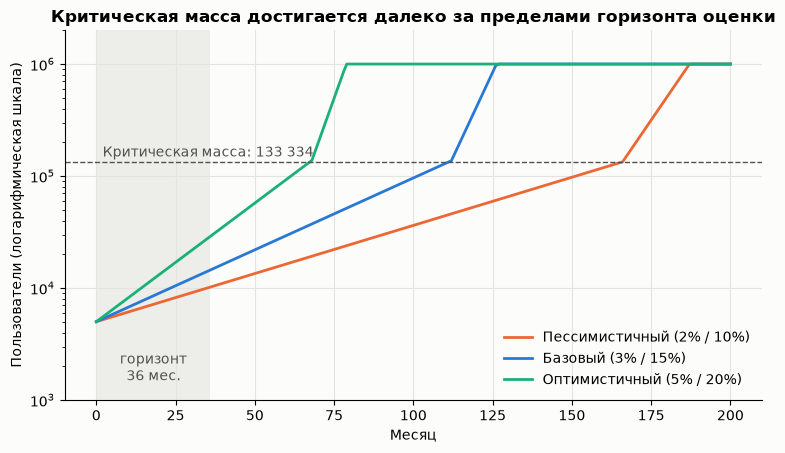

In [12]:
# График 1. Рост числа пользователей и критическая масса (длинный горизонт, логарифмическая шкала)
fig, ax = plt.subplots()
for (name, (g_before, g_after)), color in zip(growth_scenarios.items(), (C_ORANGE, C_BLUE, C_AQUA)):
    run = simulate({**BASE, "growth_before": g_before, "growth_after": g_after}, horizon=200)
    ax.plot(run.index, run["Пользователи"], color=color, linewidth=2, label=name)
ax.axhline(n_crit, color="#52514e", linewidth=1, linestyle="--")
ax.text(2, n_crit * 1.12, f"Критическая масса: {math.ceil(n_crit):,}".replace(",", " "), color="#52514e")
ax.axvspan(0, 36, color="#e4e3df", alpha=0.6, linewidth=0)
ax.text(18, 1500, "горизонт\n36 мес.", ha="center", color="#52514e")
ax.set_yscale("log")
ax.set_ylim(1000, 2_000_000)
ax.set_xlabel("Месяц")
ax.set_ylabel("Пользователи (логарифмическая шкала)")
ax.set_title("Критическая масса достигается далеко за пределами горизонта оценки")
ax.legend(frameon=False, loc="lower right")
fig.savefig(os.path.join(FIG_DIR, "02_growth.png"), dpi=160, bbox_inches="tight")
plt.show()

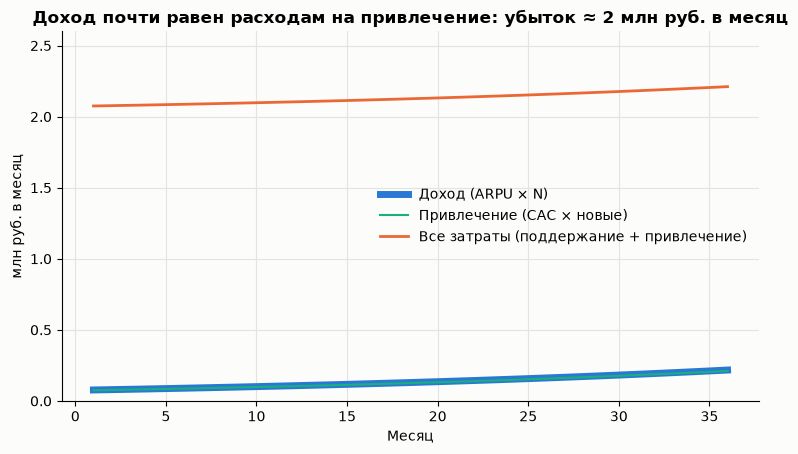

In [13]:
# График 2. Доход и затраты по месяцам в базовом сценарии
fig, ax = plt.subplots()
m = base_run.index[1:]
ax.plot(m, base_run["Доход"][1:] / MLN, color=C_BLUE, linewidth=5, label="Доход (ARPU × N)")
ax.plot(m, base_run["Привлечение"][1:] / MLN, color=C_AQUA, linewidth=1.5, label="Привлечение (CAC × новые)")
ax.plot(m, (base_run["Поддержание"] + base_run["Привлечение"])[1:] / MLN, color=C_ORANGE, linewidth=2,
        label="Все затраты (поддержание + привлечение)")
ax.set_ylim(0, 2.6)
ax.set_xlabel("Месяц")
ax.set_ylabel("млн руб. в месяц")
ax.set_title("Доход почти равен расходам на привлечение: убыток ≈ 2 млн руб. в месяц")
ax.legend(frameon=False, loc="center right")
fig.savefig(os.path.join(FIG_DIR, "02_revenue_costs.png"), dpi=160, bbox_inches="tight")
plt.show()

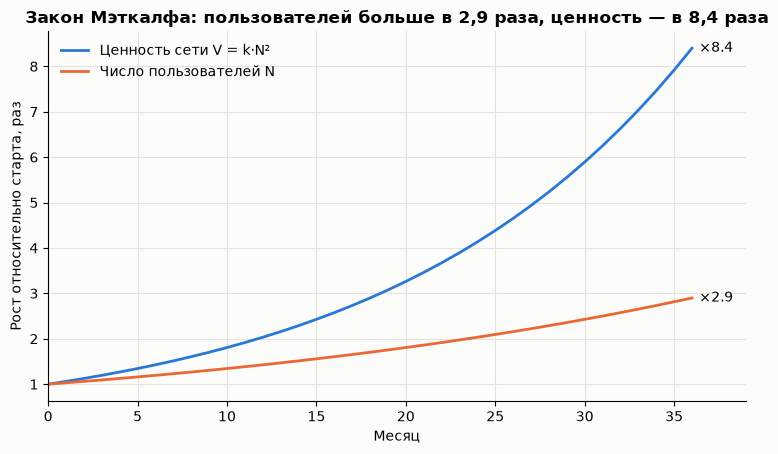

In [14]:
# График 3. Закон Мэткалфа: ценность сети растет быстрее числа пользователей
fig, ax = plt.subplots()
index_users = base_run["Пользователи"] / base_run["Пользователи"].iloc[0]
index_value = base_run["Ценность (Мэткалф)"] / base_run["Ценность (Мэткалф)"].iloc[0]
ax.plot(base_run.index, index_value, color=C_BLUE, linewidth=2, label="Ценность сети V = k·N²")
ax.plot(base_run.index, index_users, color=C_ORANGE, linewidth=2, label="Число пользователей N")
ax.text(36.4, index_value.iloc[-1], f"×{index_value.iloc[-1]:.1f}", va="center")
ax.text(36.4, index_users.iloc[-1], f"×{index_users.iloc[-1]:.1f}", va="center")
ax.set_xlim(0, 39)
ax.set_xlabel("Месяц")
ax.set_ylabel("Рост относительно старта, раз")
ax.set_title("Закон Мэткалфа: пользователей больше в 2,9 раза, ценность — в 8,4 раза")
ax.legend(frameon=False, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "02_metcalfe.png"), dpi=160, bbox_inches="tight")
plt.show()

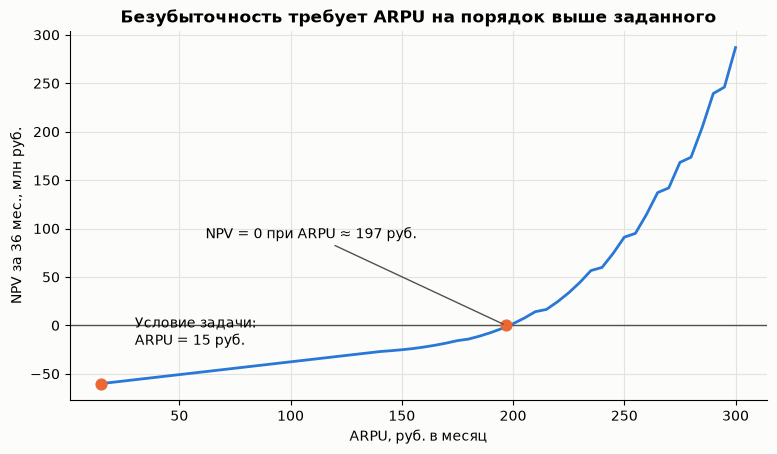

In [15]:
# График 4. NPV в зависимости от ARPU
fig, ax = plt.subplots()
ax.plot(arpu_grid, npv_arpu_curve / MLN, color=C_BLUE, linewidth=2)
ax.axhline(0, color="#52514e", linewidth=1)
ax.scatter([arpu_dynamic], [0], color=C_ORANGE, s=60, zorder=3)
ax.annotate(f"NPV = 0 при ARPU ≈ {arpu_dynamic:.0f} руб.", (arpu_dynamic, 0), xytext=(arpu_dynamic - 135, 90),
            arrowprops={"arrowstyle": "-", "color": "#52514e"})
ax.scatter([BASE["arpu"]], [npv_base / MLN], color=C_ORANGE, s=60, zorder=3)
ax.annotate("Условие задачи:\nARPU = 15 руб.", (BASE["arpu"], npv_base / MLN), xytext=(30, -20))
ax.set_xlabel("ARPU, руб. в месяц")
ax.set_ylabel("NPV за 36 мес., млн руб.")
ax.set_title("Безубыточность требует ARPU на порядок выше заданного")
fig.savefig(os.path.join(FIG_DIR, "02_npv_arpu.png"), dpi=160, bbox_inches="tight")
plt.show()

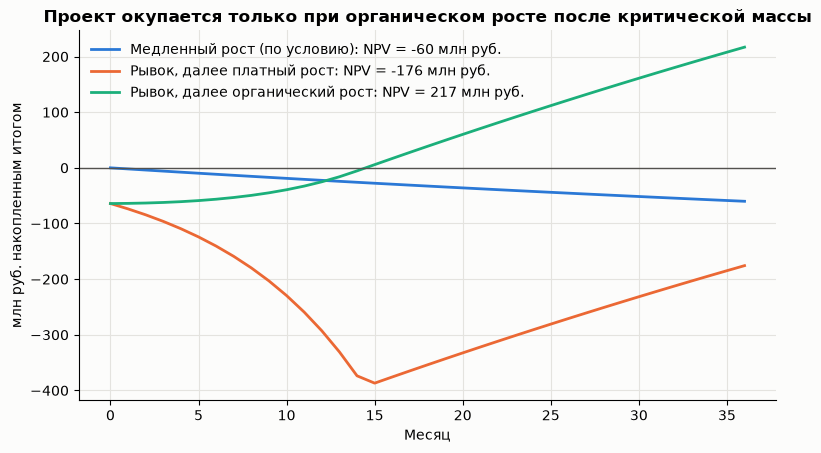

In [16]:
# График 5. Накопленный дисконтированный денежный поток по стратегиям
fig, ax = plt.subplots()
for (name, df), color in zip(strategies.items(), (C_BLUE, C_ORANGE, C_AQUA)):
    cum = df["Дисконтированная прибыль"].cumsum() / MLN
    ax.plot(df.index, cum, color=color, linewidth=2, label=f"{name}: NPV = {cum.iloc[-1]:.0f} млн руб.")
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xlabel("Месяц")
ax.set_ylabel("млн руб. накопленным итогом")
ax.set_title("Проект окупается только при органическом росте после критической массы")
ax.legend(frameon=False, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "02_strategies.png"), dpi=160, bbox_inches="tight")
plt.show()

In [17]:
# Сохраняем ключевые показатели в файл — он используется при подготовке отчета
summary = {
    "n_crit": n_crit, "t_analytic": t_analytic, "t_crit": t_crit, "t_saturation": t_saturation,
    "n_36": n_36, "v_start": v_start, "v_end": v_end,
    "v_crit": BASE["k"] * n_crit ** 2, "v_market": BASE["k"] * BASE["market"] ** 2,
    "revenue_36": base_run["Доход"].sum(), "fixed_36": base_run["Поддержание"].sum(),
    "cac_36": base_run["Привлечение"].sum(), "profit_36": base_run["Прибыль"].sum(),
    "npv_base": npv_base, "scenarios": scenario_table.to_dict(orient="index"),
    "payback_user": payback_user, "ltv_36": ltv_36,
    "arpu_fixed": arpu_fixed, "arpu_dynamic": arpu_dynamic, "arpu_operating": arpu_operating,
    "boost_6m": boost_6m, "cost_6m": cost_6m, "t_crit_boost": t_crit_boost,
    "users_to_buy": users_to_buy, "cac_to_crit": cac_to_crit,
    "strategies": strategy_table.to_dict(orient="index"), "payback_organic": payback_organic,
    "t_sat_organic": month_reached(organic, BASE["market"]),
    "monthly": base_run.loc[[1, 12, 24, 36]].to_dict(orient="index"),
}
with open(os.path.join("..", "reports", "02_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=float)
print("Показатели сохранены в reports/02_summary.json")

Показатели сохранены в reports/02_summary.json


## 4. Анализ результатов

### 4.1. Интерпретация полученных данных

- **Критическая масса — 133 334 пользователя (13,3% населения города).** Это в 26,7 раза больше стартовой базы.
- **При темпе 3% в месяц критическая масса достигается на 112-м месяце (9,3 года)** — втрое позже конца горизонта.
  За 36 месяцев сеть вырастает только до 14,5 тыс. пользователей (10,9% критической массы).
- **Сеть теряет около 2 млн руб. каждый месяц.** Доход с пользователя (15 руб.) полностью уходит на оплату роста
  (500 руб. × 3% = 15 руб.), поэтому затраты на поддержание не покрываются совсем. За 36 месяцев доход составляет
  4,9 млн руб. при затратах 76,7 млн руб.
- **NPV = −60,1 млн руб.** В заданных условиях проект неэффективен.
- **Привлечение пользователя не окупается на горизонте оценки.** CAC возвращается за 33,3 месяца, а с учетом
  дисконтирования пользователь за 36 месяцев приносит 452 руб. при цене привлечения 500 руб. (LTV/CAC = 0,90).
- **Закон Мэткалфа.** Число пользователей за 36 месяцев выросло в 2,9 раза, а ценность сети — в 8,4 раза (с 0,125 до
  1,05 млн руб.). При критической массе ценность составила бы 88,9 млн руб., при полном охвате города — 5 млрд руб.
  Основная ценность сети создается после критической массы, до которой проект в базовом варианте не доходит.

### 4.2. Сравнение с альтернативными вариантами

- **Темпы роста (задание 7).** NPV почти не меняется: −59,1 млн руб. (пессимистичный), −60,1 (базовый),
  −63,7 (оптимистичный). Быстрый рост в пределах горизонта даже ухудшает NPV, потому что расходы на привлечение растут,
  а критическая масса все равно не достигается (68-й месяц в лучшем случае).
- **ARPU (задание 8).** Проект становится безубыточным при ARPU ≈ 197 руб. в месяц — в 13 раз выше заданного. Если
  траектория роста не меняется, нужен ARPU ≈ 243 руб. Монетизация на уровне 15 руб. недостаточна для сети такого размера.
- **Ускорение на 6 месяцев (задание 9).** Достаточно разово привлечь на старте 970 пользователей за 485 тыс. руб. Это
  экономит 6 месяцев затрат на поддержание (12 млн руб.), то есть каждый рубль ускорения возвращает около 25 рублей.
- **Стратегия «рывка».** Расходы на привлечение до критической массы одинаковы при любой скорости — 64,2 млн руб.
  Медленный рост добавляет к ним 224 млн руб. затрат на поддержание за 112 месяцев. Если купить всех недостающих
  пользователей сразу, а дальше сеть растет органически, то рынок насыщается на 15-м месяце и NPV = +216,9 млн руб.
  Если же и после критической массы за каждого пользователя платить 500 руб., NPV = −175,7 млн руб.

## 5. Выводы и рекомендации

### 5.1. Ключевые выводы

1. Критическая масса сети — **133 334 пользователя**; при заданном темпе 3% она достигается на **112-м месяце**, за
   пределами горизонта.
2. NPV проекта за 36 месяцев — **−60,1 млн руб.**; в пессимистичном и оптимистичном сценариях −59,1 и −63,7 млн руб.
3. Причина убытков — сочетание низкого ARPU, дорогого привлечения и высоких постоянных затрат: предельный
   самофинансируемый темп роста равен ARPU / CAC = 3%, и при нем на поддержание сети не остается ничего.
4. Безубыточный ARPU — около **197 руб.** в месяц; ускорение на 6 месяцев стоит **485 тыс. руб.**
5. Проект может быть прибыльным только если после критической массы рост действительно становится органическим: исход
   определяет сетевой эффект, а не объем закупки пользователей.

### 5.2. Практические рекомендации для «ГородСоцСеть» (задание 10)

1. **Не растягивать путь до критической массы.** Каждый месяц ожидания стоит 2 млн руб. Бюджет на привлечение нужно
   концентрировать в начале, а не распределять равномерно.
2. **Набирать критическую массу локально.** Запускаться не на весь город, а по районам, вузам, жилым комплексам: в малом
   сообществе плотность связей и ощутимая польза достигаются быстрее и дешевле.
3. **Снижать CAC за счет сетевого эффекта.** Реферальные программы, приглашения друзей, партнерства с городскими
   организациями и событиями — рост должен становиться органическим как можно раньше.
4. **Повышать ARPU.** 15 руб. в месяц не покрывают даже стоимость роста. Нужны дополнительные источники дохода: реклама
   местного бизнеса, платные объявления, сервисы для организаций.
5. **Снижать постоянные затраты на раннем этапе** (облачная инфраструктура с оплатой по потреблению, минимальная
   команда): чем ниже затраты на поддержание, тем ниже критическая масса.
6. **Проверить гипотезу органического роста на пилоте** до крупных вложений: если после достижения локальной
   критической массы сеть не начинает расти сама, масштабировать проект нельзя.
7. **Решить проблему «курицы и яйца»**: стартовый контент и ценность без сети (городские новости, афиша, сервисы),
   чтобы первым пользователям было зачем приходить.